# CA2: Statistical technique for Data Analysis

## Project Title: Statistical Analysis of Depression Prevalence Among Older Adults Across Countries: A Global Comparative Study (1990–2023)

### Lecturer(s): Taufique Ahmed



#### Dataset Description

Global Burden of Disease Collaborative Network. Global Burden of Disease Study 2023 (GBD 2023). Seattle, United States: Institute for Health Metrics and Evaluation (IHME), 2025. Available from [IHME, Global Burden of Disease (2025)](https://vizhub.healthdata.org/gbd-results/) 

The `val` variable represents the estimated depression prevalence rate per 100,000 population. The `lower` and `upper` variables indicate the lower and upper bounds of the 95% uncertainty interval, respectively.

## 1. Introduction

This CA2 research expands the analytical perspective global population-level prevalence. This study applies statistical techniques to investigate international differences and temporal patterns.

## 2. Import necessary libraries and Load Dataset

In [1]:
# Import libraries used across the notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load dataset
df = pd.read_csv("IHME-GBD_2023_DATA-Global-1.csv")

The IHME Global Burden of Disease 2023 dataset was successfully loaded into a Pandas DataFrame

## 3. Dataset Inspection

In [3]:
# Display dataset
display(df.head())
display(df.tail())

,population_group_id,population_group_name,measure_id,measure_name,location_id,location_name,sex_id,sex_name,age_id,age_name,cause_id,cause_name,metric_id,metric_name,year,val,upper,lower
0,1,All Population,5,Prevalence,38,Mongolia,1,Male,17,60-64 years,567,Depressive disorders,3,Rate,1990,3110.875334,4082.632139,2318.468600
1,1,All Population,5,Prevalence,38,Mongolia,2,Female,17,60-64 years,567,Depressive disorders,3,Rate,1990,4683.797762,5983.796224,3585.181457
2,1,All Population,5,Prevalence,38,Mongolia,1,Male,18,65-69 years,567,Depressive disorders,3,Rate,1990,3130.898877,4001.377857,2376.084179
3,1,All Population,5,Prevalence,38,Mongolia,2,Female,18,65-69 years,567,Depressive disorders,3,Rate,1990,4720.660139,5953.136411,3608.595159
4,1,All Population,5,Prevalence,38,Mongolia,1,Male,19,70-74 years,567,Depressive disorders,3,Rate,1990,3151.444214,3934.790463,2415.426351


,population_group_id,population_group_name,measure_id,measure_name,location_id,location_name,sex_id,sex_name,age_id,age_name,cause_id,cause_name,metric_id,metric_name,year,val,upper,lower
97099,1,All Population,5,Prevalence,22,Fiji,2,Female,30,80-84 years,567,Depressive disorders,3,Rate,2023,4387.484326,6282.676154,3080.355335
97100,1,All Population,5,Prevalence,22,Fiji,1,Male,31,85-89 years,567,Depressive disorders,3,Rate,2023,4163.763555,6149.727164,2940.389887
97101,1,All Population,5,Prevalence,22,Fiji,2,Female,31,85-89 years,567,Depressive disorders,3,Rate,2023,4340.700009,6126.616778,3063.903547
97102,1,All Population,5,Prevalence,22,Fiji,1,Male,32,90-94 years,567,Depressive disorders,3,Rate,2023,4169.435564,6025.214283,2921.680271
97103,1,All Population,5,Prevalence,22,Fiji,2,Female,32,90-94 years,567,Depressive disorders,3,Rate,2023,4312.311304,5875.241076,3119.091079


In [4]:
# Dataset dimensions
print("Dataset Rows:", df.shape[0])
print("Dataset Columns:", df.shape[1])
print("Dataset shape:", df.shape)

Dataset Rows: 97104
Dataset Columns: 18
Dataset shape: (97104, 18)


In [5]:
# Dataset Information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 97104 entries, 0 to 97103
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   population_group_id    97104 non-null  int64  
 1   population_group_name  97104 non-null  str    
 2   measure_id             97104 non-null  int64  
 3   measure_name           97104 non-null  str    
 4   location_id            97104 non-null  int64  
 5   location_name          97104 non-null  str    
 6   sex_id                 97104 non-null  int64  
 7   sex_name               97104 non-null  str    
 8   age_id                 97104 non-null  int64  
 9   age_name               97104 non-null  str    
 10  cause_id               97104 non-null  int64  
 11  cause_name             97104 non-null  str    
 12  metric_id              97104 non-null  int64  
 13  metric_name            97104 non-null  str    
 14  year                   97104 non-null  int64  
 15  val          

In [6]:
# Check column names
print("Column names:") 
display(df.columns.tolist())

Column names:


['population_group_id',
 'population_group_name',
 'measure_id',
 'measure_name',
 'location_id',
 'location_name',
 'sex_id',
 'sex_name',
 'age_id',
 'age_name',
 'cause_id',
 'cause_name',
 'metric_id',
 'metric_name',
 'year',
 'val',
 'upper',
 'lower']

In [7]:
# Display descriptive statistics for the dataset
# Check the basic statistical values
print("Descriptive statistics:")
print(df.describe())

Descriptive statistics:
       population_group_id  measure_id   location_id        sex_id  \
count              97104.0     97104.0  97104.000000  97104.000000   
mean                   1.0         5.0    136.299020      1.500000   
std                    0.0         0.0     97.922111      0.500003   
min                    1.0         5.0      6.000000      1.000000   
25%                    1.0         5.0     62.750000      1.000000   
50%                    1.0         5.0    122.500000      1.500000   
75%                    1.0         5.0    182.250000      2.000000   
max                    1.0         5.0    522.000000      2.000000   

             age_id  cause_id  metric_id          year           val  \
count  97104.000000   97104.0    97104.0  97104.000000  97104.000000   
mean      23.857143     567.0        3.0   2006.500000   4351.748473   
std        6.266236       0.0        0.0      9.810759   1238.183383   
min       17.000000     567.0        3.0   1990.000000   

In [8]:
# Numerical Summary
# Check the basic statistical values ​​of numerical variables
numerical_columns = df.select_dtypes(include="number").columns
display(df[numerical_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
population_group_id,97104.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
measure_id,97104.0,5.000000,0.000000,5.000000,5.000000,5.000000,5.000000,5.000000
location_id,97104.0,136.299020,97.922111,6.000000,62.750000,122.500000,182.250000,522.000000
sex_id,97104.0,1.500000,0.500003,1.000000,1.000000,1.500000,2.000000,2.000000
age_id,97104.0,23.857143,6.266236,17.000000,18.000000,20.000000,31.000000,32.000000
cause_id,97104.0,567.000000,0.000000,567.000000,567.000000,567.000000,567.000000,567.000000
metric_id,97104.0,3.000000,0.000000,3.000000,3.000000,3.000000,3.000000,3.000000
year,97104.0,2006.500000,9.810759,1990.000000,1998.000000,2006.500000,2015.000000,2023.000000
val,97104.0,4351.748473,1238.183383,1466.927519,3480.409446,4174.813049,5100.006659,11692.639516
upper,97104.0,5503.932753,1588.849397,1775.843810,4398.391785,5350.989895,6425.176575,15517.212758


**Interpretation of Dataset Inspection**

The dataset contains 97,104 observations and 20 variables, covering geographical locations, years (1990–2023), age groups, and sexes. Initial inspection confirmed that the dataset includes the demographic and prevalence-related variables required for further statistical analysis.

## 4. Data Quality Assessment

### 4.1 Data Quality Checks

In [9]:
# Check missing values
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
population_group_id      0
population_group_name    0
measure_id               0
measure_name             0
location_id              0
location_name            0
sex_id                   0
sex_name                 0
age_id                   0
age_name                 0
cause_id                 0
cause_name               0
metric_id                0
metric_name              0
year                     0
val                      0
upper                    0
lower                    0
dtype: int64


In [10]:
# Check Duplicate Records
df.duplicated().sum()

np.int64(0)

In [11]:
# Check data types
print((df.dtypes))

population_group_id        int64
population_group_name        str
measure_id                 int64
measure_name                 str
location_id                int64
location_name                str
sex_id                     int64
sex_name                     str
age_id                     int64
age_name                     str
cause_id                   int64
cause_name                   str
metric_id                  int64
metric_name                  str
year                       int64
val                      float64
upper                    float64
lower                    float64
dtype: object


In [12]:
# Year range
print("Minimum year:", df["year"].min())
print("Maximum year:", df["year"].max())
print("Unique years:", df["year"].nunique())
print("Missing years:",sorted(set(range(1990, 2024)) - set(df["year"].dropna().unique())))

Minimum year: 1990
Maximum year: 2023
Unique years: 34
Missing years: []


In [13]:
print("Age Groups:")
print(sorted(df["age_name"].dropna().unique()))

print("\nSex Categories:")
print(df["sex_name"].value_counts(dropna=False))

Age Groups:
['60-64 years', '65-69 years', '70-74 years', '75-79 years', '80-84 years', '85-89 years', '90-94 years']

Sex Categories:
sex_name
Male      48552
Female    48552
Name: count, dtype: int64


**Interpretation of Data Quality Checks**

The initial checks confirmed that the dataset contains no missing values or fully duplicated records. The data types, year coverage, age groups, and sex categories were also examined to assess data completeness and consistency.

### 4.2 Geographical Region Mapping

In [14]:
# Import country_converter
%pip install country_converter

Note: you may need to restart the kernel to use updated packages.


In [15]:
import country_converter as coco
cc = coco.CountryConverter()

#### 4.2.1 UN Region Mapping

In [16]:
# Create region mapping
locations = df["location_name"].unique()
region_mapping = pd.DataFrame({"location_name": locations,"region": cc.convert(names=locations,to="UNregion",not_found=None )})

# Create region column directly using map()
region_lookup = region_mapping.set_index("location_name")["region"]
df["region"] = df["location_name"].map(region_lookup)

In [17]:
df.columns.tolist()

['population_group_id',
 'population_group_name',
 'measure_id',
 'measure_name',
 'location_id',
 'location_name',
 'sex_id',
 'sex_name',
 'age_id',
 'age_name',
 'cause_id',
 'cause_name',
 'metric_id',
 'metric_name',
 'year',
 'val',
 'upper',
 'lower',
 'region']

In [18]:
# Check columns
print("Region column exists:", "region" in df.columns)

# Display UN subregions
region_summary = (df.groupby("region")["location_name"].nunique().sort_values(ascending=False))
display(region_summary)

Region column exists: True


region
Eastern Africa               18
Western Asia                 18
Western Africa               16
Caribbean                    15
Southern Europe              14
South America                12
South-eastern Asia           11
Eastern Europe               10
Northern Europe              10
Southern Asia                 9
Middle Africa                 9
Polynesia                     8
Central America               8
Western Europe                8
Northern Africa               6
Micronesia                    6
Eastern Asia                  6
Central Asia                  5
Southern Africa               5
Northern America              4
Melanesia                     4
Australia and New Zealand     2
Name: location_name, dtype: int64

In [19]:
region_summary = (df.groupby("region")
    .agg(
        total_observations=("val", "count"),
        total_locations=("location_name", "nunique"),
        mean_prevalence=("val", "mean"),
        median_prevalence=("val", "median"),
        std_prevalence=("val", "std")
    ).round(2).sort_values("total_locations", ascending=False))
display(region_summary)

,total_observations,total_locations,mean_prevalence,median_prevalence,std_prevalence
region,,,,,
Eastern Africa,8568,18,4861.43,4756.29,1073.17
Western Asia,8568,18,5005.42,4873.66,1364.79
Western Africa,7616,16,4532.67,4505.66,767.34
Caribbean,7140,15,4376.74,4190.01,1098.45
Southern Europe,6664,14,3704.98,3401.39,1109.71
South America,5712,12,4006.45,3782.14,1161.16
South-eastern Asia,5236,11,3255.17,3117.90,899.95
Eastern Europe,4760,10,4298.76,4091.36,1358.15
Northern Europe,4760,10,4017.56,3787.62,1072.43


In [20]:
print(df["region"].isnull().sum())

0


**Interpretation of UN Region Mapping**

The geographical locations were successfully mapped to United Nations (UN) regional classifications using the Country Converter library. No unmatched locations were identified, allowing the dataset to be grouped by geographical subregions.

#### 4.2.2 Geographical Region Mapping

In [21]:
#Create Geographical Region Mapping
# Map UN subregions to 5 geographical regions
subregion_to_region = {
    # Africa
    "Eastern Africa": "Africa",
    "Middle Africa": "Africa",
    "Northern Africa": "Africa",
    "Southern Africa": "Africa",
    "Western Africa": "Africa",

    # Americas
    "Caribbean": "Americas",
    "Central America": "Americas",
    "Northern America": "Americas",
    "South America": "Americas",

    # Asia
    "Central Asia": "Asia",
    "Eastern Asia": "Asia",
    "South-eastern Asia": "Asia",
    "Southern Asia": "Asia",
    "Western Asia": "Asia",

    # Europe
    "Eastern Europe": "Europe",
    "Northern Europe": "Europe",
    "Southern Europe": "Europe",
    "Western Europe": "Europe",

    # Oceania
    "Australia and New Zealand": "Oceania",
    "Melanesia": "Oceania",
    "Micronesia": "Oceania",
    "Polynesia": "Oceania"
}

In [22]:
# Create geographical region column
df["geographical_region"] = df["region"].map(subregion_to_region)
display(df["geographical_region"])

0           Asia
1           Asia
2           Asia
3           Asia
4           Asia
          ...   
97099    Oceania
97100    Oceania
97101    Oceania
97102    Oceania
97103    Oceania
Name: geographical_region, Length: 97104, dtype: str

In [23]:
df.columns.tolist()

['population_group_id',
 'population_group_name',
 'measure_id',
 'measure_name',
 'location_id',
 'location_name',
 'sex_id',
 'sex_name',
 'age_id',
 'age_name',
 'cause_id',
 'cause_name',
 'metric_id',
 'metric_name',
 'year',
 'val',
 'upper',
 'lower',
 'region',
 'geographical_region']

In [24]:
# Check columns
print("Geographical Region column exists:", "geographical_region" in df.columns)

# Display UN subregions
geographical_region_summary = (df.groupby("geographical_region")["location_name"].nunique().sort_values(ascending=False))
display(geographical_region_summary)

Geographical Region column exists: True


geographical_region
Africa      54
Asia        49
Europe      42
Americas    39
Oceania     20
Name: location_name, dtype: int64

In [25]:
# Summary by Geographical Region
geographical_region_summary = (
    df.groupby("geographical_region")
    .agg(
        total_observations=("val", "count"),
        total_locations=("location_name", "nunique"),
        mean_prevalence=("val", "mean"),
        median_prevalence=("val", "median"),
        std_prevalence=("val", "std")
    ).round(2).sort_values("total_locations", ascending=False)
)
display(geographical_region_summary)

,total_observations,total_locations,mean_prevalence,median_prevalence,std_prevalence
geographical_region,,,,,
Africa,25704,54,4921.18,4763.53,1119.76
Asia,23324,49,4395.83,4188.97,1409.10
Europe,19992,42,4012.03,3765.44,1234.16
Americas,18564,39,4115.45,3917.47,1130.13
Oceania,9520,20,3880.48,3841.33,495.33


In [26]:
print(df["geographical_region"].isnull().sum())

0


**UN Subregions → Geographical Regions**
- Africa: Eastern, Middle, Northern, Southern, Western Africa
- Americas: Caribbean, Central America, Northern America, South America
- Asia: Central, Eastern, South-eastern, Southern, Western Asia
- Europe: Eastern, Northern, Southern, Western Europe
- Oceania: Australia and New Zealand, Melanesia, Micronesia, Polynesia

In [27]:
# Check locations without region
unmatched = (df.loc[df["region"].isna(), "location_name"].drop_duplicates().sort_values())

print("Unmatched locations:")
print(unmatched.to_list())

Unmatched locations:
[]


Interpretation of Geographical Region Mapping

The UN subregions were consolidated into five geographical regions: Africa, Americas, Asia, Europe, and Oceania. All locations were successfully assigned to a geographical region, supporting regional comparisons in subsequent analyses.

### 4.3 Data Quality Summary

In [28]:
# Check missing values in geographical columns
geo_columns = ["region", "geographical_region"]

print("Missing Values in Geographical Columns")
print(df[geo_columns].isnull().sum())

Missing Values in Geographical Columns
region                 0
geographical_region    0
dtype: int64


In [29]:
# Check infinite values in prevalence estimates
numeric_columns = ["lower", "val", "upper"]
print("\nInfinite Values")

infinity_counts = np.isinf(df[numeric_columns]).sum()
print(infinity_counts)


Infinite Values
lower    0
val      0
upper    0
dtype: int64


In [30]:
# Validate uncertainty interval boundaries
invalid_intervals = df[(df["lower"] > df["val"]) | (df["val"] > df["upper"])]

print("\nInvalid Uncertainty Intervals")
print(f"Invalid records: {len(invalid_intervals)}")


Invalid Uncertainty Intervals
Invalid records: 0


In [31]:
# Validate year range and observations per year
expected_years = set(range(1990, 2024))
actual_years = set(df["year"].dropna().unique())

missing_years = sorted(expected_years - actual_years)
unexpected_years = sorted(actual_years - expected_years)

year_counts = (df.groupby("year").size().reindex(sorted(expected_years), fill_value=0))

print("\nYear Validation")
print(f"Missing years: {missing_years}")
print(f"Unexpected years: {unexpected_years}")
print("\nObservations per year:")
print(year_counts)


Year Validation
Missing years: []
Unexpected years: []

Observations per year:
year
1990    2856
1991    2856
1992    2856
1993    2856
1994    2856
1995    2856
1996    2856
1997    2856
1998    2856
1999    2856
2000    2856
2001    2856
2002    2856
2003    2856
2004    2856
2005    2856
2006    2856
2007    2856
2008    2856
2009    2856
2010    2856
2011    2856
2012    2856
2013    2856
2014    2856
2015    2856
2016    2856
2017    2856
2018    2856
2019    2856
2020    2856
2021    2856
2022    2856
2023    2856
dtype: int64


In [32]:
# Check completeness of age groups and sex categories
expected_age_groups = 7
expected_sex_categories = 2

location_year_check = (
    df.groupby(["location_name", "year"])
    .agg(
        age_groups=("age_name", "nunique"),
        sex_categories=("sex_name", "nunique"),
        combinations=("age_name", "size")
    ))

incomplete_location_years = location_year_check[
    (location_year_check["age_groups"] != expected_age_groups) |
    (location_year_check["sex_categories"] != expected_sex_categories) |
    (location_year_check["combinations"] != expected_age_groups * expected_sex_categories)
]

print("\nAge and Sex Completeness")
print(f"Location-year groups checked: {len(location_year_check)}")
print(f"Incomplete location-year groups: {len(incomplete_location_years)}")


Age and Sex Completeness
Location-year groups checked: 6936
Incomplete location-year groups: 0


In [33]:
# Summary of incomplete records
if not incomplete_location_years.empty:
    print("\nIncomplete Location-Year Details:")
    print(incomplete_location_years.head(10))

In [34]:
key_columns = ["location_name","year","age_name","sex_name","cause_name","measure_name","metric_name"]

In [35]:
quality_summary = pd.DataFrame({
    "Check": [
        "Total observations",
        "Total variables",
        "Missing values",
        "Fully duplicated rows",
        "Duplicate observations",
        "Negative prevalence values",
        "Missing location names", 
        "Missing year values"
    ],
    "Result": [
        len(df),
        df.shape[1],
        df.isna().sum().sum(),
        df.duplicated().sum(),
        df.duplicated(subset=key_columns).sum(),
        (df["val"] < 0).sum(),
        df["location_name"].isnull().sum(),
        df["year"].isnull().sum()
    ]
})

display(quality_summary)

,Check,Result
0,Total observations,97104
1,Total variables,20
2,Missing values,0
3,Fully duplicated rows,0
4,Duplicate observations,0
5,Negative prevalence values,0
6,Missing location names,0
7,Missing year values,0


**Interpretation of Data Quality Summary**

The final assessment confirmed good structural data quality, with no missing values, duplicate records, negative prevalence estimates, infinite values, or invalid uncertainty intervals. All 34 years (1990–2023) and expected age and sex categories were represented across the examined location-year groups.

## 5. Descriptive Statistics

In [36]:
# Overall descriptive statistics
overall_stats = df["val"].describe()
overall_stats.loc["IQR"] = ( overall_stats["75%"] - overall_stats["25%"])
display(overall_stats)

count    97104.000000
mean      4351.748473
std       1238.183383
min       1466.927519
25%       3480.409446
50%       4174.813049
75%       5100.006659
max      11692.639516
IQR       1619.597213
Name: val, dtype: float64

**Interpretation of Overall descriptive statistics**

The overall descriptive statistics show that the dataset contains 97,104 prevalence estimates, with a mean of 4,351.75 and a median of 4,174.81. The standard deviation is 1,238.18, indicating considerable variation across observations. Values range from 1,466.93 to 11,692.64, with an interquartile range (IQR) of 1,619.60. The mean being higher than the median suggests a positively skewed distribution.

In [37]:
# Descriptive statistics by age group
age_stats = (df.groupby("age_name")["val"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        SD="std",
        Minimum="min",
        Maximum="max",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    ))

age_stats["IQR"] = age_stats["Q3"] - age_stats["Q1"]
display(age_stats.round(2).T)

age_name,60-64 years,65-69 years,70-74 years,75-79 years,80-84 years,85-89 years,90-94 years
Count,13872.00,13872.00,13872.00,13872.00,13872.00,13872.00,13872.00
Mean,4379.18,4395.44,4355.46,4330.16,4314.78,4326.37,4360.85
Median,4184.32,4224.45,4193.68,4166.27,4148.50,4146.91,4163.72
SD,1289.33,1283.66,1255.85,1233.99,1213.43,1197.24,1187.97
Minimum,1466.93,1476.00,1470.04,1470.65,1477.59,1523.47,1591.25
Maximum,11692.64,11646.99,11434.53,11255.79,11101.39,11003.21,10995.67
Q1,3457.94,3481.77,3463.20,3455.68,3455.51,3486.36,3536.95
Q3,5191.44,5155.56,5104.08,5069.37,5045.90,5049.36,5094.49
IQR,1733.50,1673.79,1640.87,1613.69,1590.38,1563.00,1557.54


**Interpretation of Descriptive statistics by Age Group**

The descriptive statistics show relatively similar mean estimates across all age groups, ranging from 4,314.78 to 4,395.44. The highest mean was observed in the 65–69 years group, while the lowest was recorded in the 80–84 years group. Standard deviations and interquartile ranges generally decrease with age, indicating slightly lower variability among older age groups. Overall, the differences in mean estimates across age groups are relatively small.

In [38]:
# Descriptive statistics by year
year_stats = (df.groupby("year")["val"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        SD="std",
        Minimum="min",
        Maximum="max",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    ))
year_stats["IQR"] = year_stats["Q3"] - year_stats["Q1"]
display(year_stats.round(2).T)

year,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
Count,2856.00,2856.00,2856.00,2856.00,2856.00,2856.00,2856.00,2856.00,2856.00,2856.00,...,2856.00,2856.00,2856.00,2856.00,2856.00,2856.00,2856.00,2856.00,2856.00,2856.00
Mean,4025.19,4051.61,4072.86,4066.52,4113.46,4109.50,4124.37,4158.24,4153.24,4178.95,...,4348.71,4360.36,4379.28,4388.49,4410.07,4417.77,5176.37,5254.52,5181.09,5271.92
Median,3810.88,3856.37,3868.24,3868.73,3915.19,3910.68,3922.37,3962.20,3964.43,3981.97,...,4167.65,4192.36,4223.06,4226.32,4246.56,4254.07,4889.62,4991.88,4902.57,4987.06
SD,1049.73,1051.52,1069.16,1071.19,1086.96,1087.44,1101.38,1120.01,1119.61,1138.92,...,1189.13,1189.93,1204.05,1199.12,1203.31,1209.57,1482.02,1496.10,1473.24,1507.48
Minimum,1474.70,1539.83,1472.06,1504.20,1561.62,1470.65,1499.69,1499.93,1472.55,1473.77,...,1471.35,1470.04,1474.48,1480.26,1488.00,1496.57,1617.32,1711.10,1660.31,1678.25
Maximum,7907.54,7711.79,7982.10,7794.79,7810.64,8015.92,8119.90,8317.85,8428.85,8705.62,...,9543.39,9645.94,9683.60,9703.90,9696.88,9669.15,11583.43,11692.64,11360.29,11632.47
Q1,3316.05,3328.47,3348.07,3353.02,3376.59,3375.01,3389.80,3377.14,3370.60,3389.06,...,3526.92,3536.77,3538.63,3553.69,3567.52,3591.77,4152.91,4235.67,4174.10,4220.50
Q3,4760.55,4788.76,4814.62,4817.99,4862.53,4866.48,4905.17,4937.62,4943.83,4970.37,...,5122.83,5121.97,5155.37,5170.75,5193.60,5214.05,6148.31,6280.24,6162.57,6314.88
IQR,1444.51,1460.29,1466.55,1464.97,1485.94,1491.46,1515.36,1560.49,1573.22,1581.30,...,1595.91,1585.20,1616.73,1617.05,1626.08,1622.27,1995.39,2044.58,1988.47,2094.37


**Interpretation of Descriptive Statistics by Year**

The mean depression prevalence estimates (val) show a gradual increase from 4,025.19 in 1990 to 4,417.77 in 2019. A substantial increase is observed from 2020 onwards, with the mean reaching 5,271.92 in 2023, the highest value in the period.

The standard deviation also increases over time, indicating greater variation in the estimates across locations. Overall, the results suggest an upward trend in average depression prevalence estimates between 1990 and 2023.

In [39]:
# Descriptive Statistics by genders
sex_stats = (df.groupby("sex_name")["val"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        SD="std",
        Minimum="min",
        Maximum="max",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    ))
sex_stats["IQR"] = sex_stats["Q3"] - sex_stats["Q1"]
display(sex_stats.round(2).T)

sex_name,Female,Male
Count,48552.00,48552.00
Mean,5104.18,3599.32
Median,5018.29,3546.97
SD,1110.95,836.48
Minimum,1787.99,1466.93
Maximum,11692.64,9228.06
Q1,4317.18,3050.14
Q3,5716.90,4040.10
IQR,1399.72,989.96


**Interpretation of Descriptive Statistics by Gender**

The mean depression prevalence rate was higher among females (5,104.18 per 100,000) than males (3,599.32 per 100,000). The median values showed a similar pattern, at 5,018.29 and 3,546.97, respectively.

Females also showed greater variability in prevalence rates, with a standard deviation of 1,110.95 compared with 836.48 among males. Overall, the results indicate higher estimated depression prevalence rates among females across the countries, years, and age groups analysed.

In [125]:
# Descriptive Statistics by Location
country_stats = (df.groupby("location_name")["val"]
    .agg(
            Count="count",
            Mean="mean",
            Median="median",
            SD="std",
            Minimum="min",
            Maximum="max",
            Q1=lambda x: x.quantile(0.25),
            Q3=lambda x: x.quantile(0.75)
        ))
country_stats["IQR"] = country_stats["Q3"] - country_stats["Q1"]
display(country_stats.round(2).T)

location_name,Afghanistan,Albania,Algeria,American Samoa,Andorra,Angola,Antigua and Barbuda,Argentina,Armenia,Australia,...,United States Virgin Islands,United States of America,Uruguay,Uzbekistan,Vanuatu,Venezuela (Bolivarian Republic of),Viet Nam,Yemen,Zambia,Zimbabwe
Count,476.00,476.00,476.00,476.00,476.00,476.00,476.00,476.00,476.00,476.00,...,476.00,476.00,476.00,476.00,476.00,476.00,476.00,476.00,476.00,476.00
Mean,5530.04,3786.81,5306.83,3992.52,3824.87,6427.88,4285.27,3412.49,4758.82,3640.14,...,3602.38,3698.34,3171.36,4590.60,3915.62,4396.76,3362.68,5310.59,4540.00,4207.44
Median,5449.58,3722.91,5275.93,3931.83,3944.09,6700.87,4563.96,3587.90,4879.01,3566.14,...,3813.01,3755.63,3194.93,4615.89,3833.66,4659.53,3381.01,5191.56,4740.92,4371.42
SD,823.12,778.01,714.50,396.52,1015.21,1233.68,1014.95,898.70,1069.02,325.60,...,661.30,852.84,1137.47,976.36,383.39,962.29,776.06,879.25,723.70,642.04
Minimum,4366.79,2564.66,3907.87,3316.58,2654.55,4891.75,3003.29,2335.91,3133.11,3143.63,...,2739.36,2629.61,1947.66,3133.26,3316.15,3201.58,2391.55,3776.87,3489.24,3250.13
Maximum,8121.28,5529.49,7322.90,5023.41,6245.60,9493.66,6684.73,5931.88,7442.74,4567.48,...,5114.18,6284.07,5829.44,6541.75,4956.52,6383.38,4852.44,7900.66,6491.22,5944.27
Q1,4839.41,3065.47,4745.36,3745.56,2826.60,5164.72,3253.92,2540.02,3711.36,3373.99,...,2939.99,2892.94,2037.69,3636.89,3668.27,3412.97,2612.24,4642.61,3852.36,3631.98
Q3,6030.94,4467.72,5796.77,4236.63,4572.10,7368.75,5064.48,4065.47,5536.06,3855.05,...,4121.60,4300.96,4105.42,5488.47,4093.59,5210.92,4099.69,5843.91,5052.78,4649.20
IQR,1191.53,1402.25,1051.41,491.07,1745.50,2204.03,1810.55,1525.44,1824.70,481.06,...,1181.61,1408.02,2067.73,1851.59,425.32,1797.94,1487.46,1201.30,1200.42,1017.22


**Interpretation of Descriptive Statistics by Location**

The descriptive statistics highlight variations in depression prevalence rates across countries between 1990 and 2023. Differences in mean and median values indicate variations in the estimated prevalence rates, while the standard deviation reflects the degree of variability within each country. These findings provide an overview of geographical differences in depression prevalence among older adults. All rates are expressed per 100,000 population.

In [126]:
# Descriptive Statistics by region
region_stats = (df.groupby("region")["val"]
    .agg(
            Count="count",
            Mean="mean",
            Median="median",
            SD="std",
            Minimum="min",
            Maximum="max",
            Q1=lambda x: x.quantile(0.25),
            Q3=lambda x: x.quantile(0.75)
        ))
region_stats["IQR"] = region_stats["Q3"] - region_stats["Q1"]
display(region_stats.round(2).T)

region,Australia and New Zealand,Caribbean,Central America,Central Asia,Eastern Africa,Eastern Asia,Eastern Europe,Melanesia,Micronesia,Middle Africa,...,Northern Europe,Polynesia,South America,South-eastern Asia,Southern Africa,Southern Asia,Southern Europe,Western Africa,Western Asia,Western Europe
Count,952.00,7140.00,3808.00,2380.00,8568.00,2856.00,4760.00,1904.00,2856.00,4284.00,...,4760.00,3808.00,5712.00,5236.00,2380.00,4284.00,6664.00,7616.00,8568.00,3808.00
Mean,3187.37,4376.74,4036.37,4479.67,4861.43,4176.41,4298.76,3896.79,3997.22,5819.56,...,4017.56,3958.05,4006.45,3255.17,4233.79,4670.51,3704.98,4532.67,5005.42,4184.05
Median,3290.24,4190.01,4124.44,4334.02,4756.29,3883.13,4091.36,3816.99,3910.64,5327.99,...,3787.62,3878.63,3782.14,3117.90,4089.88,4583.15,3401.39,4505.66,4873.66,4110.42
SD,588.63,1098.45,1087.80,1023.87,1073.17,1575.35,1358.15,421.28,422.48,1376.43,...,1072.43,409.69,1161.16,899.95,622.10,1189.35,1109.71,767.34,1364.79,1342.35
Minimum,2134.28,2739.36,2396.16,2766.27,2573.06,1805.64,2389.49,3128.34,3313.70,3451.23,...,2335.84,3269.88,1877.15,1466.93,3279.31,2591.08,1845.30,3125.18,1972.05,1973.96
Maximum,4567.48,8289.85,7511.18,7296.89,8903.77,8117.11,10327.50,5596.42,5860.59,9718.12,...,7611.69,5552.06,7516.74,6588.75,6544.93,8780.55,7939.77,7896.65,11692.64,9124.05
Q1,2720.37,3319.18,3013.30,3618.59,3972.82,3112.70,3147.15,3608.10,3716.55,4776.20,...,3138.10,3693.80,3188.58,2678.78,3702.38,3753.27,2876.91,3925.12,3978.71,3084.23
Q3,3577.85,5156.89,4763.81,5415.89,5677.24,5066.67,5131.42,4085.64,4197.48,6888.51,...,4962.75,4147.01,5018.35,3950.22,4696.37,5507.00,4483.50,5017.15,5786.98,5048.75
IQR,857.48,1837.71,1750.51,1797.30,1704.42,1953.98,1984.27,477.54,480.93,2112.31,...,1824.65,453.21,1829.77,1271.44,994.00,1753.73,1606.59,1092.02,1808.27,1964.53


**Interpretation of Descriptive Statistics by region**

The descriptive statistics reveal differences in depression prevalence rates across the five geographical regions. Africa recorded the highest mean prevalence rate (4,921.18 per 100,000 population), followed by Asia (4,395.83), the Americas (4,115.45), Europe (4,012.03), and Oceania (3,880.48). Asia showed the greatest variability (SD = 1,409.10), whereas Oceania had the lowest variability (SD = 495.33). These findings highlight geographical differences in estimated depression prevalence rates among older adults across the study period.

In [127]:
# Descriptive Statistics by geographical_region
geographical_region_stats = (df.groupby("geographical_region")["val"]
    .agg(
            Count="count",
            Mean="mean",
            Median="median",
            SD="std",
            Minimum="min",
            Maximum="max",
            Q1=lambda x: x.quantile(0.25),
            Q3=lambda x: x.quantile(0.75)
        ))
geographical_region_stats["IQR"] = geographical_region_stats["Q3"] - geographical_region_stats["Q1"]
geographical_region_stats.round(2).T

geographical_region,Africa,Americas,Asia,Europe,Oceania
Count,25704.00,18564.00,23324.00,19992.00,9520.00
Mean,4921.18,4115.45,4395.83,4012.03,3880.48
Median,4763.53,3917.47,4188.97,3765.44,3841.33
SD,1119.76,1130.13,1409.10,1234.16,495.33
Minimum,2573.06,1877.15,1466.93,1845.30,2134.28
Maximum,9718.12,8289.85,11692.64,10327.50,5860.59
Q1,4043.60,3213.33,3455.60,3011.44,3611.30
Q3,5531.41,5045.03,5306.22,4854.84,4128.66
IQR,1487.81,1831.70,1850.62,1843.40,517.36


**Interpretation of Descriptive Statistics by Geographical Region**

The descriptive statistics reveal differences in depression prevalence rates across the five geographical regions. Africa recorded the highest mean rate (4,921.18 per 100,000 population), followed by Asia (4,395.83), the Americas (4,115.45), Europe (4,012.03), and Oceania (3,880.48). Asia showed the greatest variability (SD = 1,409.10), while Oceania had the lowest (SD = 495.33). These findings indicate geographical variations in estimated depression prevalence rates among older adults across the study period.

In [128]:
# Descriptive statistics by age group and year
age_year_stats = (
    df.groupby(["year", "age_name"])["val"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        SD="std"
    )
    .reset_index()
)
display(age_year_stats.round(2))

,year,age_name,Count,Mean,Median,SD
0,1990,60-64 years,408,4060.80,3815.57,1106.75
1,1990,65-69 years,408,4065.34,3843.74,1095.43
2,1990,70-74 years,408,4020.65,3812.32,1064.57
3,1990,75-79 years,408,3990.21,3788.76,1039.63
4,1990,80-84 years,408,3976.64,3778.87,1019.31
...,...,...,...,...,...,...
233,2023,70-74 years,408,5284.57,4990.62,1529.64
234,2023,75-79 years,408,5267.71,4982.79,1506.35
235,2023,80-84 years,408,5255.75,4974.06,1485.31
236,2023,85-89 years,408,5252.88,4984.16,1467.74


**Interpretation of Descriptive Statistics by Age Group and Year**

The descriptive statistics provide an overview of depression prevalence rates across different age groups from 1990 to 2023. Comparing the mean and median values helps identify differences in prevalence rates between age groups over time, while the standard deviation indicates variations in estimates across locations and sexes. This analysis provides a basis for examining age-related and temporal patterns in depression prevalence among older adults.

## EDA - Exploratory Data Analysis

### Introduction to Exploratory Data Analysis

Exploratory Data Analysis (EDA) was conducted to examine the distribution and variation of depression prevalence estimates among adults aged 60 years and above. The analysis covers 204 geographical locations, five geographical regions, seven age groups and both sexes over the period 1990–2023.

Descriptive statistics and visualisations, including histograms, boxplots, scatter plots, line charts and heatmaps, are used to explore differences across geographical regions, age groups and sexes, as well as changes over time. These analyses provide an overview of the patterns, variability and potential differences within the dataset.

The findings from EDA provide a descriptive foundation for the subsequent hypothesis testing, which will investigate whether selected differences between population groups are statistically significant.

### Histogram – Overall Distribution of Depression Prevalence

To examine the overall distribution of depression prevalence estimates across all geographical locations, years (1990–2023), age groups and sexes.

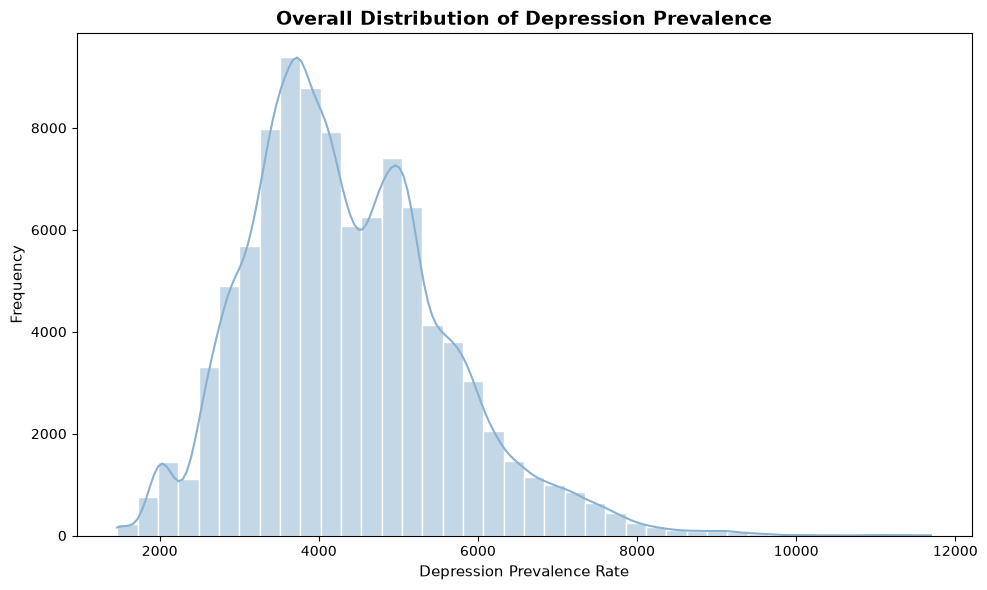

In [129]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data
hist_df = df["val"].dropna()

# Create histogram
plt.figure(figsize=(10, 6))
sns.histplot(data=hist_df, bins=40, kde=True, color="#89B1D1", edgecolor="white")

plt.title("Overall Distribution of Depression Prevalence", fontsize=14, fontweight="bold")
plt.xlabel("Depression Prevalence Rate", fontsize=11)
plt.ylabel("Frequency", fontsize=11)

plt.tight_layout()
plt.show()

In [130]:
# Summary statistics
overall_summary = hist_df.describe()
print(hist_df.describe())
print("\nSkewness:", round(hist_df.skew(), 3))
print("\nKurtosis:", round(hist_df.kurtosis(), 3))

count    97104.000000
mean      4351.748473
std       1238.183383
min       1466.927519
25%       3480.409446
50%       4174.813049
75%       5100.006659
max      11692.639516
Name: val, dtype: float64

Skewness: 0.67

Kurtosis: 0.798


**Histogram – Overall Distribution of Depression Prevalence**

A histogram was constructed to examine the overall distribution of depression prevalence estimates across geographical locations, years, age groups and sexes from 1990 to 2023. The histogram provides an overview of the distribution's shape, concentration, spread and potential skewness. These characteristics help describe the variability of depression prevalence estimates within the dataset.

### age group

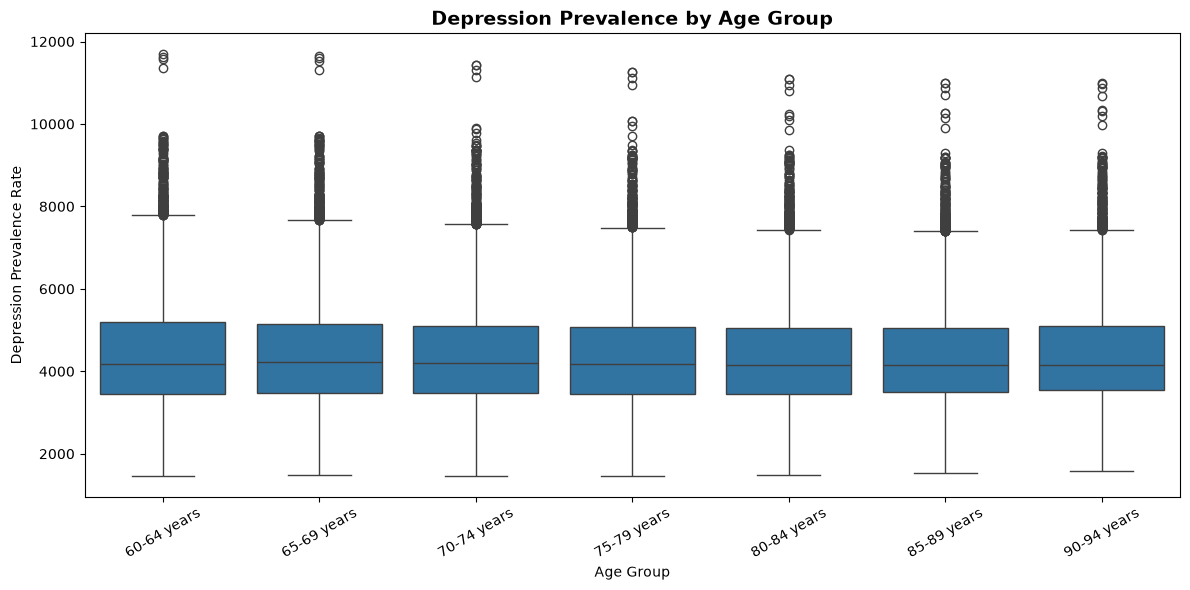

In [131]:
import re
age_df = df.dropna(
    subset=["age_name", "val"]
).copy()

# Sort age groups by their starting age
age_order = sorted(
    age_df["age_name"].unique(),
    key=lambda x: int(re.search(r"\d+", x).group())
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=age_df,
    x="age_name",
    y="val",
    order=age_order,
    showfliers=True
)

plt.title(
    "Depression Prevalence by Age Group",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Age Group")
plt.ylabel("Depression Prevalence Rate")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [132]:
age_summary = (
    age_df.groupby("age_name")["val"]
    .agg(
        observations="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .reindex(age_order)
    .round(2)
)

display(age_summary)

,observations,mean,median,std,minimum,maximum
age_name,,,,,,
60-64 years,13872,4379.18,4184.32,1289.33,1466.93,11692.64
65-69 years,13872,4395.44,4224.45,1283.66,1476.00,11646.99
70-74 years,13872,4355.46,4193.68,1255.85,1470.04,11434.53
75-79 years,13872,4330.16,4166.27,1233.99,1470.65,11255.79
80-84 years,13872,4314.78,4148.50,1213.43,1477.59,11101.39
85-89 years,13872,4326.37,4146.91,1197.24,1523.47,11003.21
90-94 years,13872,4360.85,4163.72,1187.97,1591.25,10995.67


### year

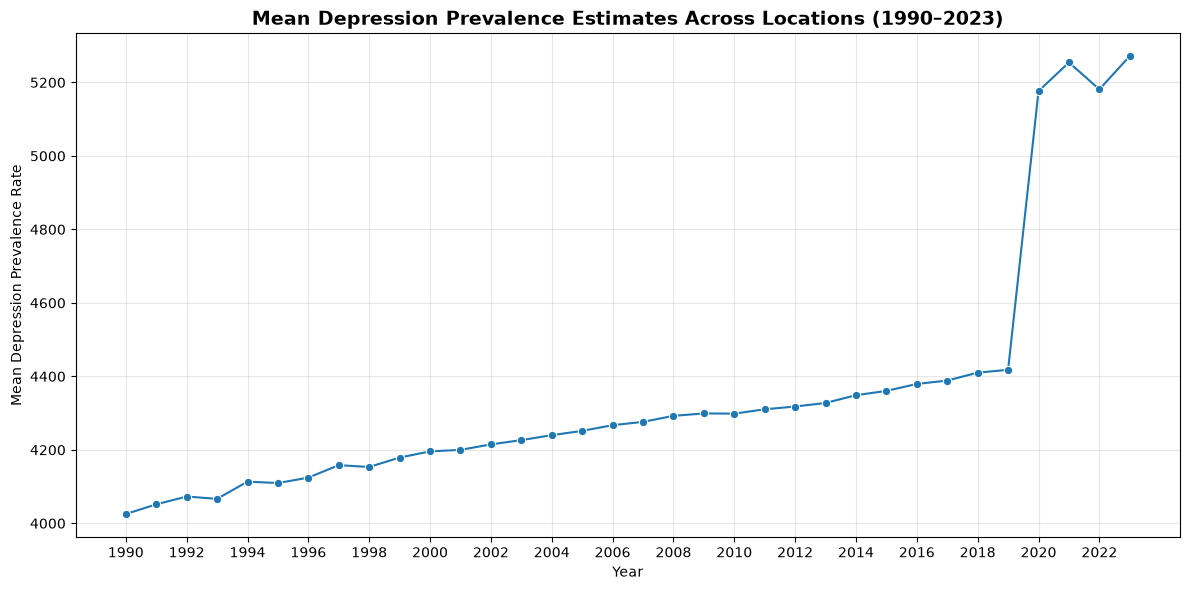

In [133]:
trend_df = df.dropna(
    subset=["year", "val"]
).copy()

global_trend = (
    trend_df.groupby("year")["val"]
    .mean()
    .reset_index(name="mean_prevalence")
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=global_trend,
    x="year",
    y="mean_prevalence",
    marker="o"
)

plt.title(
    "Mean Depression Prevalence Estimates Across Locations (1990–2023)",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Year")
plt.ylabel("Mean Depression Prevalence Rate")
plt.xticks(range(1990, 2024, 2))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [134]:
display(global_trend.round(2))

,year,mean_prevalence
0,1990,4025.19
1,1991,4051.61
2,1992,4072.86
3,1993,4066.52
4,1994,4113.46
5,1995,4109.50
6,1996,4124.37
7,1997,4158.24
8,1998,4153.24
9,1999,4178.95


### genders

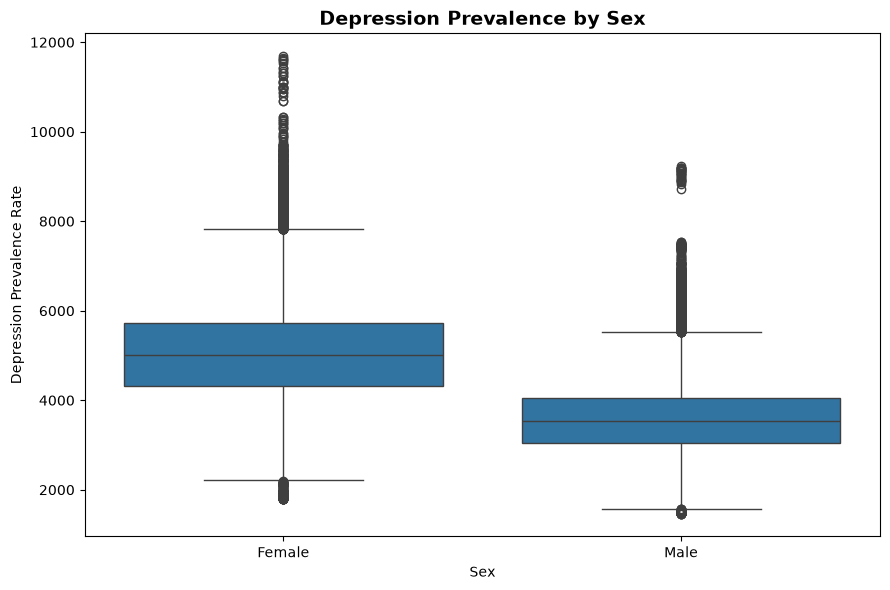

In [135]:
sex_order = ["Female", "Male"]

sex_df = df.dropna(
    subset=["sex_name", "val"]
).copy()

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=sex_df,
    x="sex_name",
    y="val",
    order=sex_order,
    showfliers=True
)

plt.title(
    "Depression Prevalence by Sex",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Sex")
plt.ylabel("Depression Prevalence Rate")

plt.tight_layout()
plt.show()

In [136]:
sex_summary = (
    sex_df.groupby("sex_name")["val"]
    .agg(
        observations="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .round(2)
)

display(sex_summary)

,observations,mean,median,std,minimum,maximum
sex_name,,,,,,
Female,48552,5104.18,5018.29,1110.95,1787.99,11692.64
Male,48552,3599.32,3546.97,836.48,1466.93,9228.06


### Histogram – By geographical_region

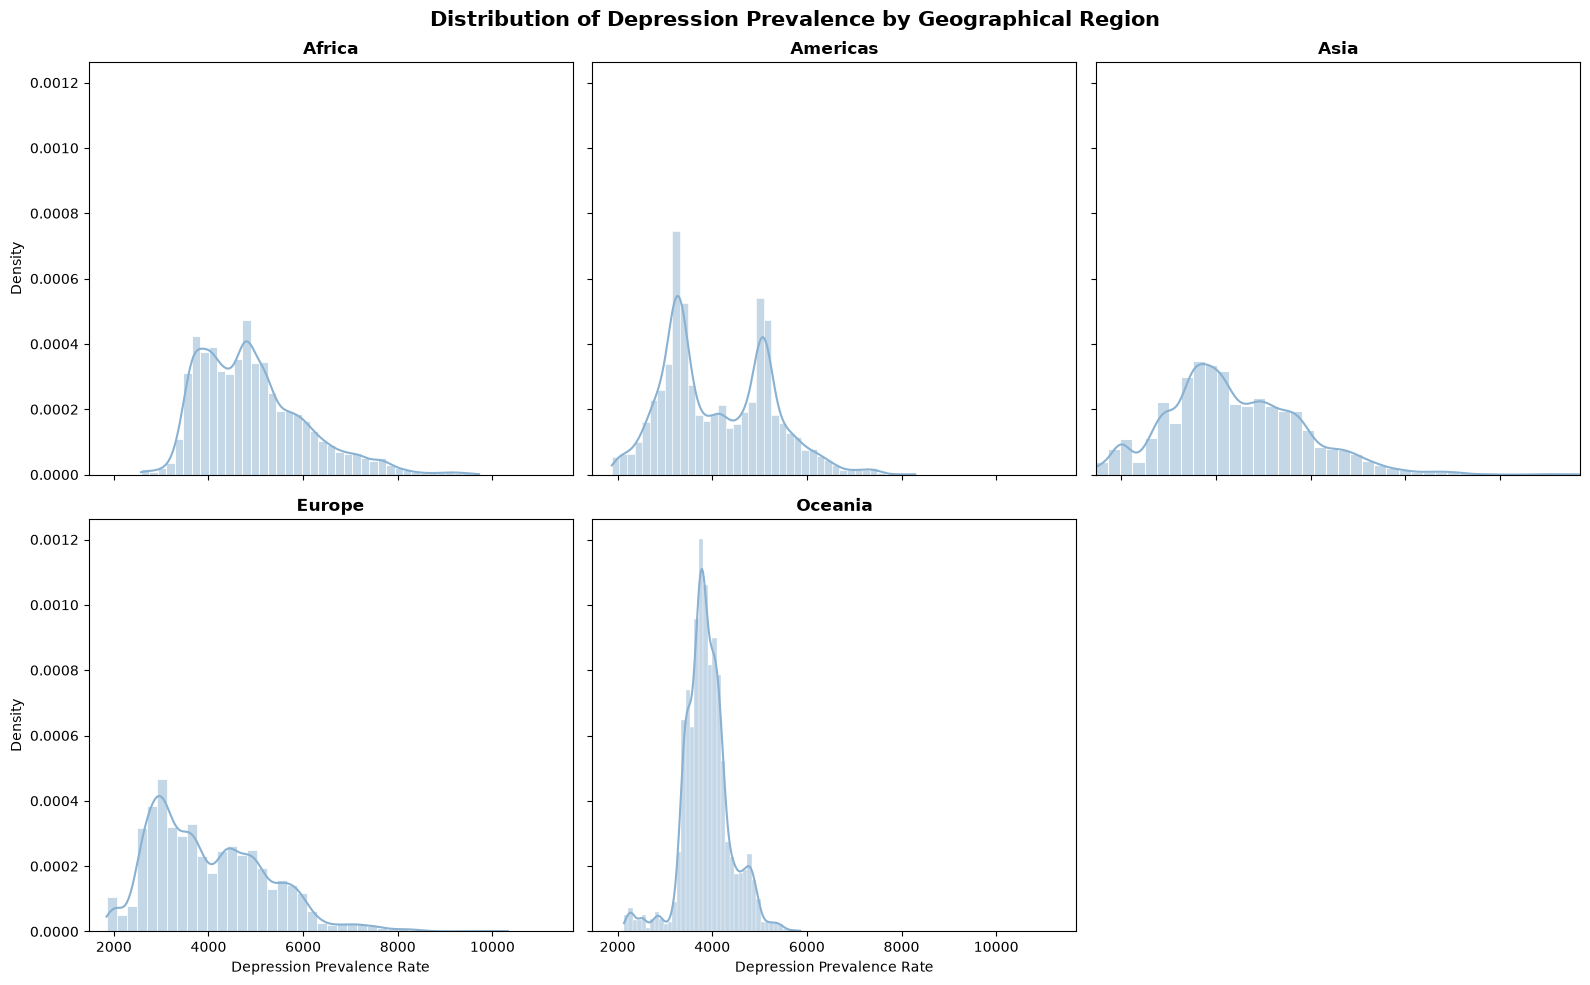

In [137]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data
hist_df = df.dropna(
    subset=["val", "geographical_region"]
).copy()

regions = sorted(hist_df["geographical_region"].unique())

# Use common bins and x-axis range
bins = 40
x_min = hist_df["val"].min()
x_max = hist_df["val"].max()

# Create subplots
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 10),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for i, region in enumerate(regions):

    region_data = hist_df.loc[
        hist_df["geographical_region"] == region,
        "val"
    ]

    sns.histplot(
        data=region_data,
        bins=bins,
        kde=True,
        stat="density",
        ax=axes[i],
        color="#89B1D1",
        edgecolor="white"
    )

    axes[i].set_title(region, fontweight="bold")
    axes[i].set_xlim(x_min, x_max)
    axes[i].set_xlabel("Depression Prevalence Rate")
    axes[i].set_ylabel("Density")

# Remove unused subplot
for j in range(len(regions), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Distribution of Depression Prevalence by Geographical Region",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

The histograms compare the distribution of depression prevalence
estimates across five geographical regions. The analysis includes
all available countries, years (1990–2023), age groups and sexes.

Using consistent histogram bins and axis scales allows the
distribution, concentration and spread of prevalence estimates
to be compared across regions.

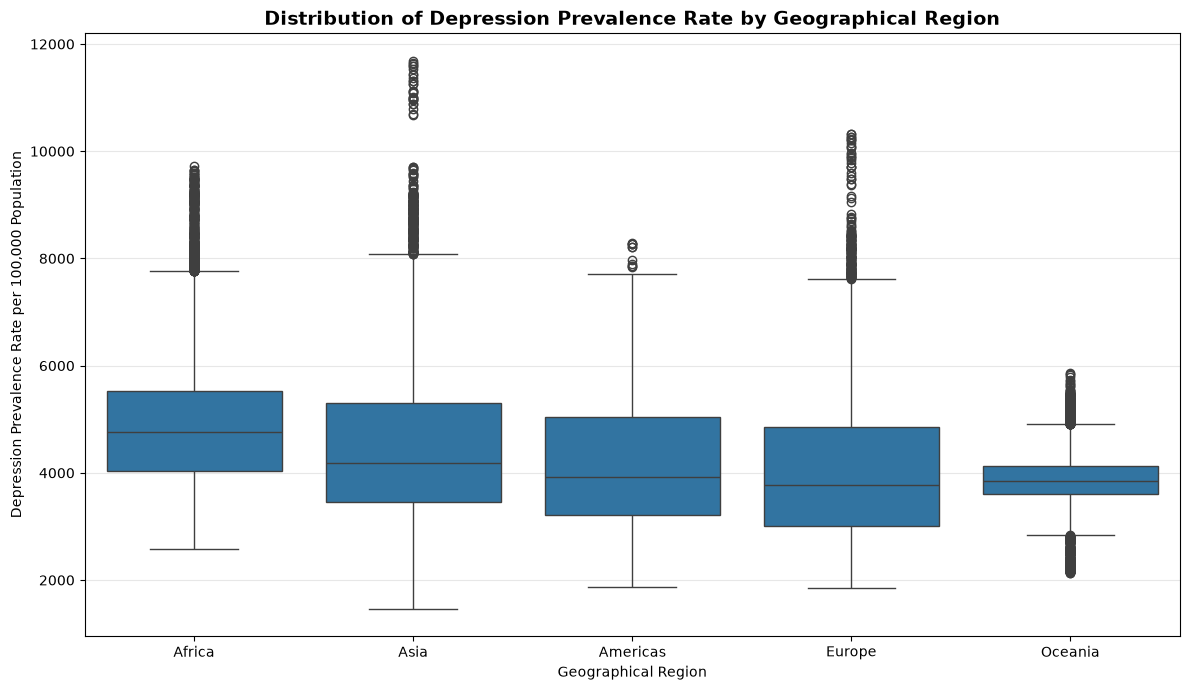

In [151]:
# Boxplot – Depression Prevalence by Geographical Region

region_order = [
    "Africa",
    "Asia",
    "Americas",
    "Europe",
    "Oceania"
]

region_df = df.dropna(
    subset=["geographical_region", "val"]
).copy()

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=region_df,
    x="geographical_region",
    y="val",
    order=region_order,
    showfliers=True
)

plt.title(
    "Distribution of Depression Prevalence Rate by Geographical Region",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Geographical Region")
plt.ylabel("Depression Prevalence Rate per 100,000 Population")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation of Distribution by Geographical Region**

The boxplot illustrates differences in the distribution of depression prevalence rates across the five geographical regions. Asia and Europe show wider distributions, indicating greater variability, while Oceania has a narrower distribution. Africa has the highest median prevalence rate, consistent with its highest mean in the descriptive statistics. Outliers are also visible across several regions, indicating observations with unusually high or low prevalence rates compared with their respective regional distributions.

### age group and year

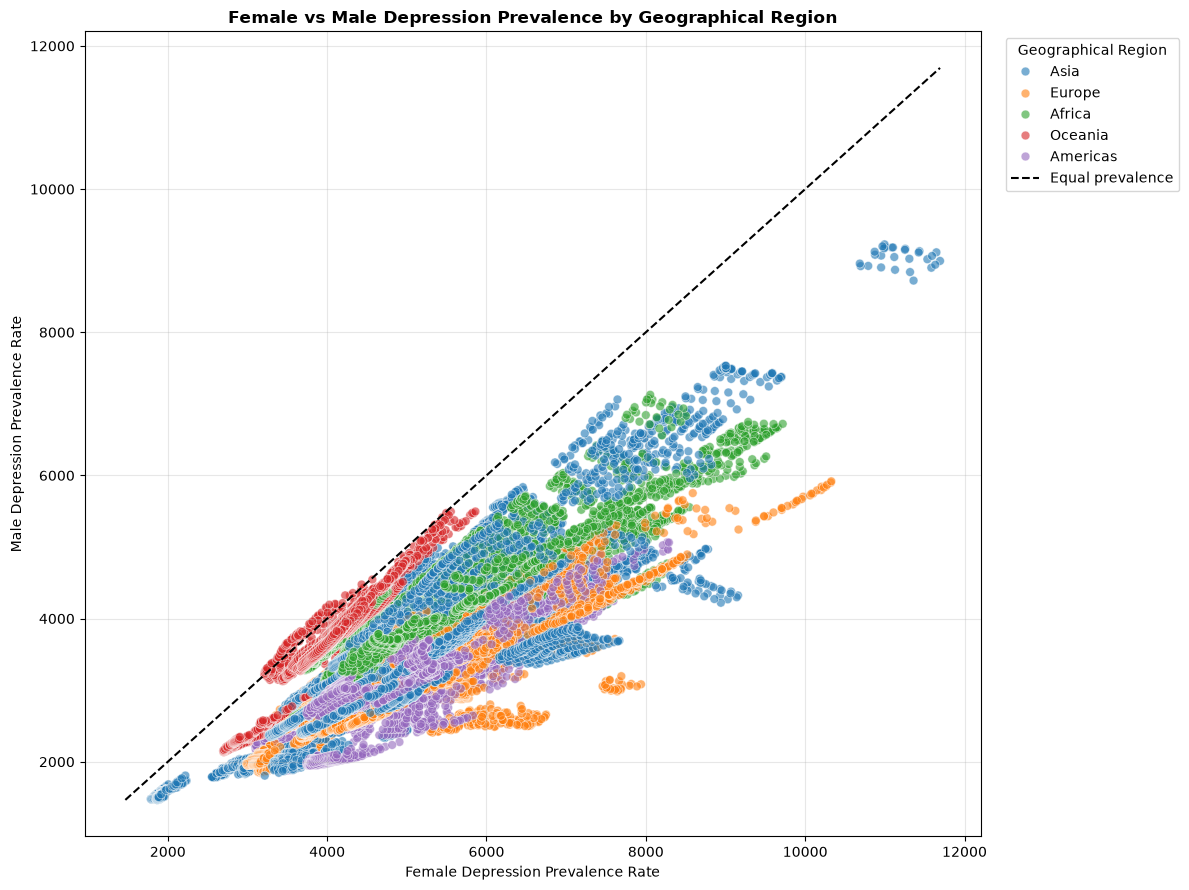

In [152]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare paired Female and Male data
scatter_df = (
    df.pivot_table(
        index=[
            "location_name",
            "year",
            "age_name",
            "geographical_region"
        ],
        columns="sex_name",
        values="val"
    )
    .dropna(subset=["Female", "Male"])
    .reset_index()
)

# Create scatter plot
plt.figure(figsize=(12, 9))

sns.scatterplot(
    data=scatter_df,
    x="Female",
    y="Male",
    hue="geographical_region",
    alpha=0.6,
    s=40
)

# Add equality reference line
min_val = min(
    scatter_df["Female"].min(),
    scatter_df["Male"].min()
)

max_val = max(
    scatter_df["Female"].max(),
    scatter_df["Male"].max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    color="black",
    label="Equal prevalence"
)

plt.title(
    "Female vs Male Depression Prevalence by Geographical Region",
    fontweight="bold"
)

plt.xlabel("Female Depression Prevalence Rate")
plt.ylabel("Male Depression Prevalence Rate")

plt.legend(
    title="Geographical Region",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The scatter plot compares female and male depression prevalence
estimates across five geographical regions.

Each point represents a matched observation for the same location,
year and age group. Colours distinguish the five geographical
regions: Africa, Americas, Asia, Europe and Oceania.

The diagonal reference line represents equal prevalence between
females and males. The distribution of points illustrates regional
patterns and differences in prevalence between the two sexes.

### Mean Prevalence Rate by Age Group (1990–2023)

#### Line Chart

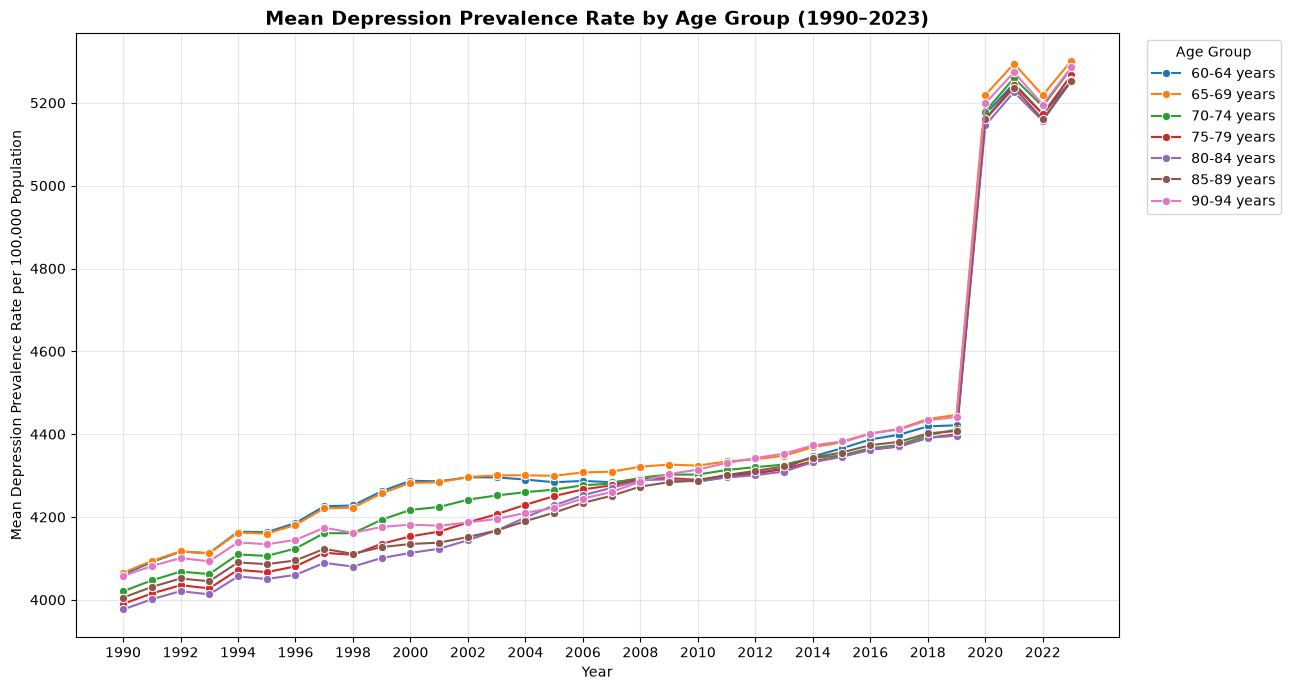

In [153]:
# Prepare age group order
import re
import matplotlib.pyplot as plt
import seaborn as sns

age_order = sorted(
    age_year_stats["age_name"].unique(),
    key=lambda x: int(re.search(r"\d+", x).group())
)

# Create line chart
plt.figure(figsize=(13, 7))

sns.lineplot(
    data=age_year_stats,
    x="year",
    y="Mean",
    hue="age_name",
    hue_order=age_order,
    marker="o"
)

plt.title(
    "Mean Depression Prevalence Rate by Age Group (1990–2023)",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Year")
plt.ylabel("Mean Depression Prevalence Rate per 100,000 Population")
plt.xticks(range(1990, 2024, 2))
plt.legend(
    title="Age Group",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Interpretation of Mean Depression Prevalence Rate per 100,000 Population**

The line chart illustrates changes in mean depression prevalence rates across seven older-adult age groups from 1990 to 2023. The trends show a gradual increase over time, followed by a more noticeable rise from 2020 onwards. The age-group lines remain relatively close, indicating broadly similar trends across age categories. These results suggest an overall increase in estimated depression prevalence rates across the study period, although the magnitude varies slightly by age group.

#### Heatmap

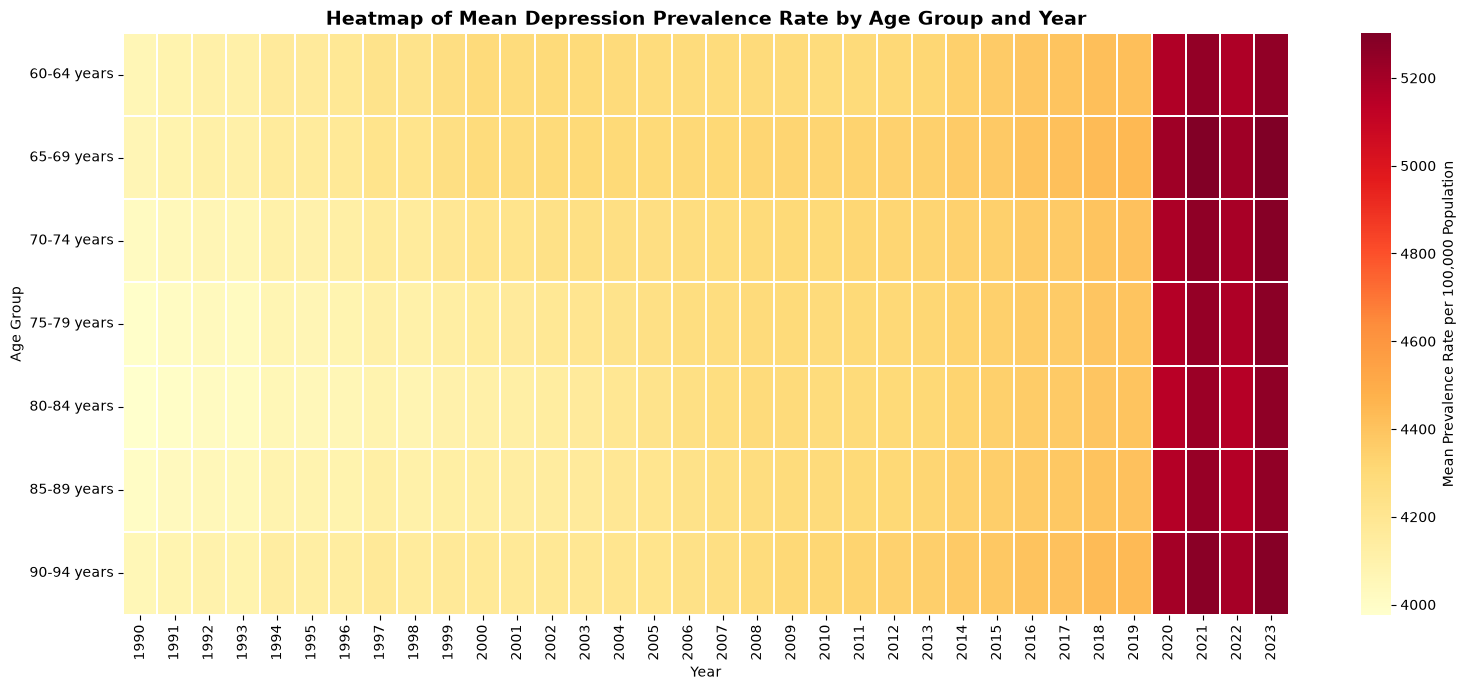

In [154]:

# Prepare data for heatmap
age_year_pivot = age_year_stats.pivot(
    index="age_name",
    columns="year",
    values="Mean"
).reindex(age_order)

# Create heatmap
plt.figure(figsize=(16, 7))

sns.heatmap(
    age_year_pivot,
    cmap="YlOrRd",
    linewidths=0.3,
    cbar_kws={
        "label": "Mean Prevalence Rate per 100,000 Population"
    }
)

plt.title(
    "Heatmap of Mean Depression Prevalence Rate by Age Group and Year",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Year")
plt.ylabel("Age Group")

plt.tight_layout()
plt.show()


Interpretation of Heatmap Mean Prevalence Rate by Age Group and Year

The heatmap highlights variations in mean depression prevalence rates across age groups and years. The colour intensity indicates differences in the estimated rates, with higher values becoming more noticeable in the later years, particularly from 2020 onwards. The pattern is broadly consistent across age groups, suggesting that the increase was not limited to a single age category. The heatmap also provides a clear overview of temporal and age-related variations within the dataset.

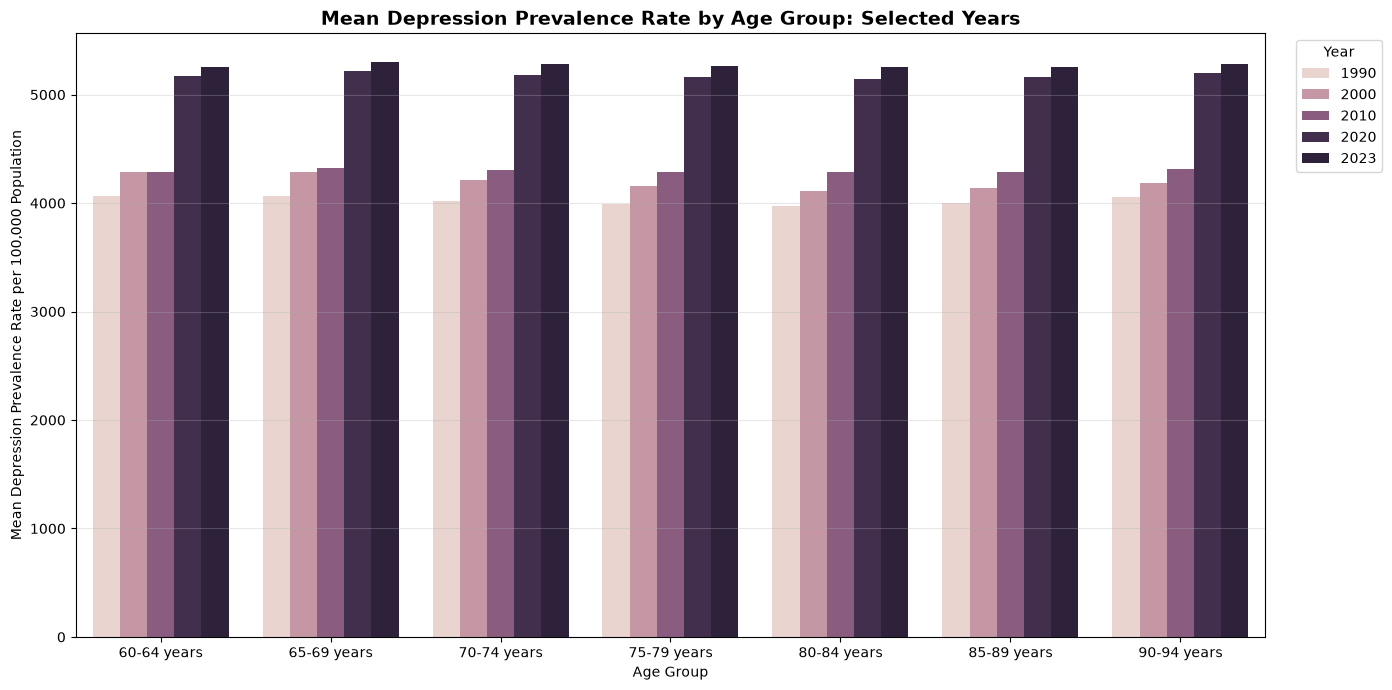

In [155]:
# Select representative years
selected_years = [1990, 2000, 2010, 2020, 2023]

bar_df = age_year_stats[
    age_year_stats["year"].isin(selected_years)
].copy()

# Create grouped bar chart
plt.figure(figsize=(14, 7))

sns.barplot(
    data=bar_df,
    x="age_name",
    y="Mean",
    hue="year",
    order=age_order,
    hue_order=selected_years
)

plt.title(
    "Mean Depression Prevalence Rate by Age Group: Selected Years",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Age Group")
plt.ylabel("Mean Depression Prevalence Rate per 100,000 Population")
plt.legend(
    title="Year",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


**Interpretation of Mean Depression Prevalence Rate per 100,000 Population**

The grouped bar chart compares mean depression prevalence rates across age groups in five selected years. The comparison shows higher mean rates in 2023 than in the earlier selected years, indicating an overall increase over the study period. Differences between age groups are relatively small compared with the changes observed across years. This suggests that temporal variation is more prominent than variation between the selected age categories.

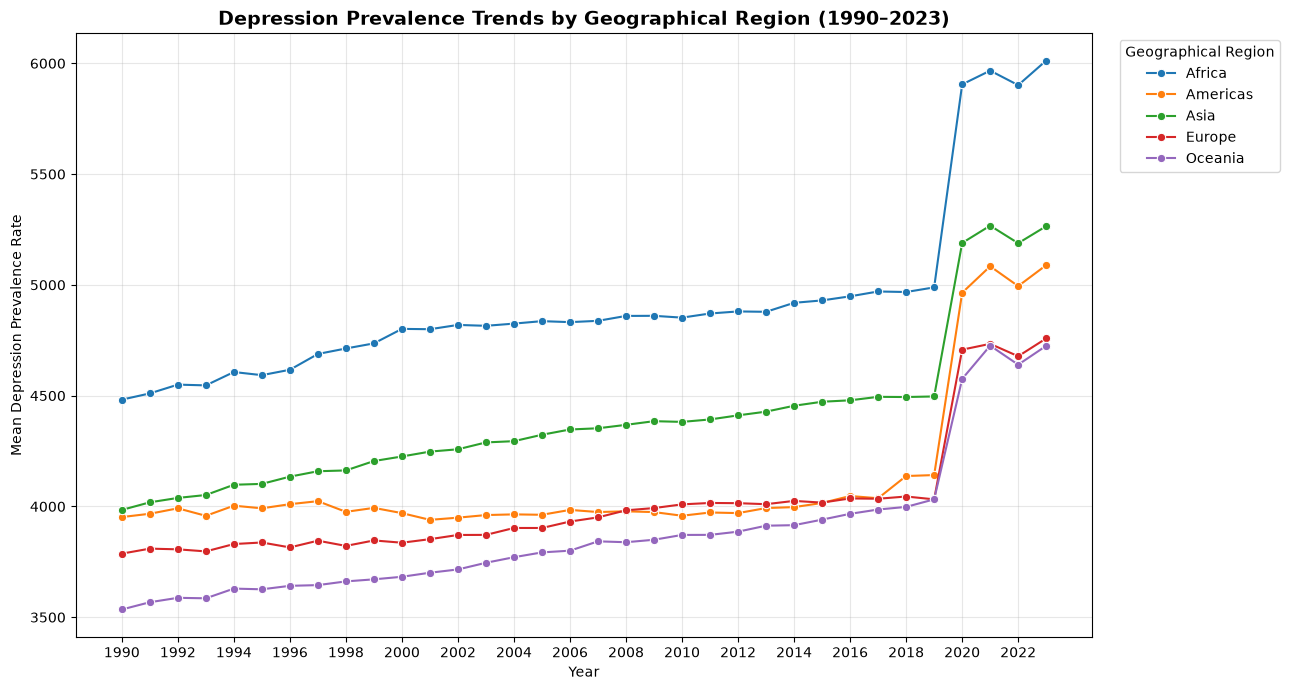

In [156]:
region_order = [
    "Africa",
    "Americas",
    "Asia",
    "Europe",
    "Oceania"
]
regional_trend = (
    df.dropna(
        subset=["year", "val", "geographical_region"]
    )
    .groupby(
        ["year", "geographical_region"]
    )["val"]
    .mean()
    .reset_index(name="mean_prevalence")
)

plt.figure(figsize=(13, 7))

sns.lineplot(
    data=regional_trend,
    x="year",
    y="mean_prevalence",
    hue="geographical_region",
    hue_order=region_order,
    marker="o"
)

plt.title(
    "Depression Prevalence Trends by Geographical Region (1990–2023)",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Year")
plt.ylabel("Mean Depression Prevalence Rate")
plt.xticks(range(1990, 2024, 2))
plt.legend(
    title="Geographical Region",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [157]:
regional_trend_pivot = regional_trend.pivot(
    index="year",
    columns="geographical_region",
    values="mean_prevalence"
)
display(regional_trend_pivot.round(2))

geographical_region,Africa,Americas,Asia,Europe,Oceania
year,,,,,
1990,4482.04,3952.06,3984.23,3786.98,3534.87
1991,4510.15,3967.00,4018.63,3809.56,3567.66
1992,4549.78,3991.58,4038.44,3806.42,3587.58
1993,4546.42,3957.67,4051.59,3797.12,3585.41
1994,4606.65,4003.48,4097.88,3830.28,3629.20
1995,4592.53,3991.46,4101.80,3837.33,3625.98
1996,4616.89,4010.28,4134.50,3815.08,3641.70
1997,4688.21,4023.75,4158.90,3845.41,3644.92
1998,4712.91,3975.59,4162.52,3821.86,3661.68


## 6. Hypothesis Testing